DSR Environment ready.


Saving ABG_LINEAR_restricted_results - Copy.xlsx to ABG_LINEAR_restricted_results - Copy.xlsx

>> Training DSR for: moving_away
-- BUILDING PRIOR START -------------
LengthConstraint: Sequences have minimum length 2.
                  Sequences have maximum length 5.
UniformArityPrior: Activated.
SoftLengthPrior: No description available.
-- BUILDING PRIOR END ---------------

-- RUNNING ITERATIONS START -------------
[00:00:00:02.44] Training iteration 1, current best R: 0.2845

	** New best
	Reward: 0.284459339888319
	Count Off-policy: 0
	Count On-policy: 67
	Originally on Policy: True
	Invalid: False
	Traversal: sub,sub,x1,x1,x1
	Expression:
	  -x₁

-- RUNNING ITERATIONS START -------------
-- RUNNING ITERATIONS START -------------
-- RUNNING ITERATIONS START -------------
-- RUNNING ITERATIONS START -------------
-- RUNNING ITERATIONS START -------------
-- RUNNING ITERATIONS START -------------
-- RUNNING ITERATIONS START -------------
-- RUNNING ITERATIONS START -------------
-- 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

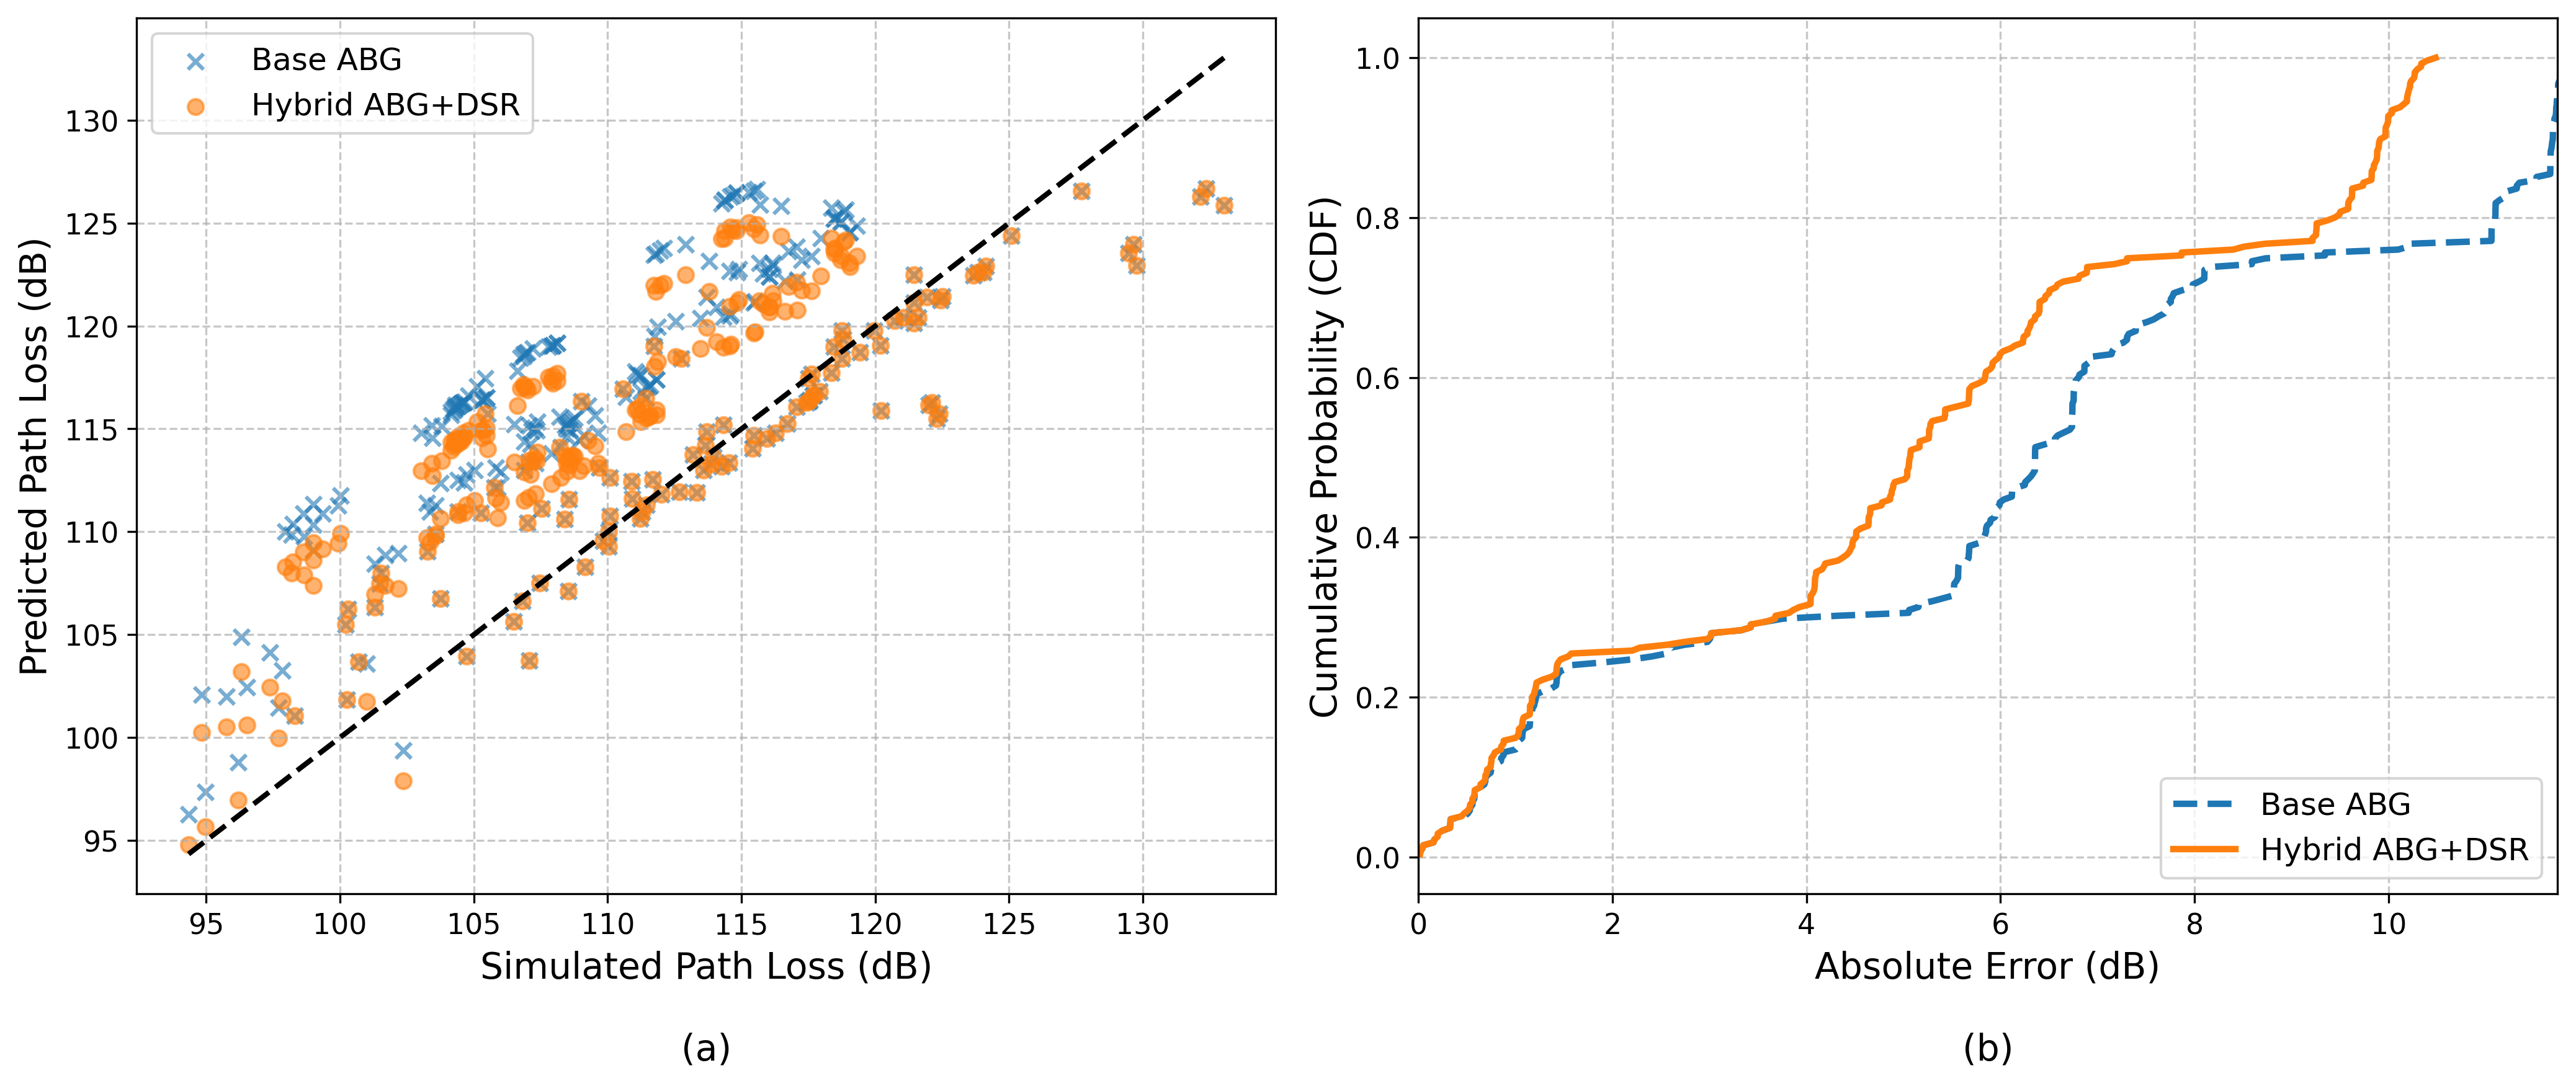


✅ تم تحديث كود DSR بالكامل! تم إضافة التحليل التفصيلي، وتصدير الأرقام للإكسل، وتجهيز الأشكال البيانية.


In [ ]:
# =========================================================
# 1) ENVIRONMENT SETUP, INSTALLATION, AND IMPORTS (DSR ONLY)
# =========================================================
import os, sys, subprocess, shutil, random, warnings, collections, collections.abc
warnings.filterwarnings("ignore")

WORK_DIR = "/content" if os.path.isdir("/content") else os.getcwd()
DSO_REPO_DIR = os.path.join(WORK_DIR, "deep-symbolic-optimization-pytorch")
DSO_SOURCE_PARENT = os.path.join(DSO_REPO_DIR, "dso")

REQUIRED_PACKAGES = [
    "numpy==1.26.4", "pandas==2.2.2", "scipy==1.13.1", "scikit-learn==1.5.2",
    "matplotlib==3.9.2", "openpyxl==3.1.5", "torch", "sympy", "click",
    "deap", "pathos", "progress", "tqdm", "commentjson", "PyYAML", "prettytable"
]

def run(cmd, quiet=True):
    completed = subprocess.run(cmd, check=False, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    if completed.returncode != 0: raise RuntimeError("Command failed:\n" + " ".join(cmd))
    return completed

def ensure_packages():
    try:
        import commentjson, deap, pathos, yaml
        import numpy as np
        if np.__version__ == "1.26.4": return
    except Exception: pass

    print("\nInstalling required packages for DSR...")
    run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools", "wheel"])
    run([sys.executable, "-m", "pip", "install", "-q", "--no-cache-dir"] + REQUIRED_PACKAGES)
    print("\n✅ Packages installed successfully!")
    raise SystemExit("⚠️ IMPORTANT: Please go to menu: Runtime > Restart session, then run this cell again.")

def ensure_dso_source():
    if os.path.isdir(os.path.join(DSO_SOURCE_PARENT, "dso")): return
    if os.path.exists(DSO_REPO_DIR): shutil.rmtree(DSO_REPO_DIR)
    run(["git", "clone", "--depth", "1", "https://github.com/dso-org/deep-symbolic-optimization-pytorch.git", DSO_REPO_DIR], quiet=False)

def patch_python312_compatibility():
    import pkgutil, zipimport, importlib.machinery as machinery
    if not hasattr(collections, "Mapping"): collections.Mapping = collections.abc.Mapping
    if not hasattr(pkgutil, "ImpImporter"):
        class ImpImporterShim:
            def __init__(self, path=None): self.path = path
            def find_module(self, fullname, path=None): return None
            def find_spec(self, fullname, target=None): return None
        pkgutil.ImpImporter = ImpImporterShim
    if not hasattr(pkgutil, "ImpLoader"):
        class ImpLoaderShim: pass
        pkgutil.ImpLoader = ImpLoaderShim
    def loader_from_spec(spec): return None if spec is None else getattr(spec, "loader", None)

    if not hasattr(machinery.FileFinder, "find_module"):
        machinery.FileFinder.find_module = lambda self, fullname, path=None: loader_from_spec(self.find_spec(fullname))
    if not hasattr(machinery.PathFinder, "find_module"):
        machinery.PathFinder.find_module = classmethod(lambda cls, fullname, path=None: loader_from_spec(cls.find_spec(fullname, path)))
    if not hasattr(zipimport.zipimporter, "find_module"):
        zipimport.zipimporter.find_module = lambda self, fullname, path=None: loader_from_spec(self.find_spec(fullname))

def patch_numpy_aliases():
    import numpy as np
    aliases = {"float": float, "int": int, "bool": bool, "object": object}
    for alias, value in aliases.items():
        if not hasattr(np, alias): setattr(np, alias, value)

def patch_dso_executor():
    execute_py = os.path.join(DSO_SOURCE_PARENT, "dso", "execute.py")
    if not os.path.isfile(execute_py): return
    with open(execute_py, "r", encoding="utf-8") as f: source = f.read()
    if "# COLAB_PATCH" in source: return
    with open(execute_py, "a", encoding="utf-8") as f:
        f.write("\n\n# COLAB_PATCH\ntry:\n    _ = cyfunc.execute\nexcept Exception:\n    cython_execute = python_execute\n")

def set_all_seeds(seed):
    random.seed(seed); import numpy as np; import torch
    np.random.seed(seed); torch.manual_seed(seed)

ensure_packages(); ensure_dso_source()
if DSO_SOURCE_PARENT not in sys.path: sys.path.insert(0, DSO_SOURCE_PARENT)
patch_python312_compatibility()
patch_numpy_aliases()
patch_dso_executor()

import numpy as np; import pandas as pd; import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
try: from dso import DeepSymbolicRegressor
except Exception as exc: raise RuntimeError("Failed to import DSO. Restart Colab.") from exc

print("DSR Environment ready.")

# =========================================================
# 2) SETTINGS & DATA LOADING
# =========================================================
SEED = 42; TEST_SIZE = 0.20
DSR_N_SAMPLES = 200000; DSR_MAX_LEN = 5; DSR_POLY_DEG = 2
OUTPUT_FILE = "DSR_Detailed_Results.xlsx"

try: from google.colab import files; uploaded = files.upload(); file_name = list(uploaded.keys())[0]
except Exception: file_name = "TrainingData.xlsx"

df = pd.read_excel(file_name, sheet_name="TrainingData") if "TrainingData" in pd.ExcelFile(file_name).sheet_names else pd.read_excel(file_name)

def normalize_phase(v):
    t = str(v).strip().lower().replace("-", "_").replace(" ", "_")
    return "moving_in" if t in ["movingin", "in", "approaching"] else "moving_away" if t in ["movingaway", "away", "receding"] else t

if "Phase Label" in df.columns: df["Phase Label"] = df["Phase Label"].apply(normalize_phase)
df = df[df["Phase Label"].isin(["moving_in", "moving_away"])].copy()

speed_col = [c for c in df.columns if "speed" in str(c).lower()][0]
df = df[df[speed_col] > 0].copy()
df["u"] = df["u_speed_log10_kmh"].astype(float)
df["delta_dB"] = df["delta_dB"].astype(float)
df = df.dropna(subset=["Path Loss (dB)", "ABG Path Loss (dB)", "Phase Label", "u", "delta_dB"])

train_df, test_df = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, stratify=df["Phase Label"])

# =========================================================
# 3) DSR TRAINING & AUTOMATIC SYMBOLIC REPHRASING
# =========================================================
import sympy
from sympy.parsing.sympy_parser import parse_expr

def make_dsr_config(seed):
    return {
        "experiment": {"seed": int(seed), "exp_name": "DSR_NoBloat"},
        "task": {"task_type": "regression", "function_set": ["add", "sub", "mul"], "protected": True, "metric": "inv_nrmse"},
        "training": {"n_samples": DSR_N_SAMPLES, "batch_size": 1000, "epsilon": 0.10, "n_cores_batch": 1},
        "prior": {"length": {"min_": 2, "max_": DSR_MAX_LEN, "on": True}, "soft_length": {"loc": 2, "scale": 0.1, "on": True}, "domain_range": {"on": False}}
    }

def calculate_complexity(sympy_expr):
    complexity = 0
    for node in sympy.preorder_traversal(sympy_expr):
        if isinstance(node, (sympy.Add, sympy.Mul, sympy.Pow, sympy.Function)):
            complexity += 1
    return complexity + 1

dsr_models, expr_rows = {}, []
for idx, scenario in enumerate(sorted(train_df["Phase Label"].unique())):
    sub = train_df[train_df["Phase Label"] == scenario]
    print(f"\n>> Training DSR for: {scenario}")
    set_all_seeds(SEED + idx)

    model = DeepSymbolicRegressor(config=make_dsr_config(SEED + idx))
    model.fit(sub[["u"]].values, sub["delta_dB"].values)
    dsr_models[scenario] = model

    raw_expr_str = model.program_.pretty() if hasattr(model, 'program_') else "Error"

    try:
        sympy_expr = parse_expr(raw_expr_str.replace("x1", "u"))
        clean_expr = sympy.simplify(sympy_expr)
        final_expr_str = str(clean_expr)
        complexity_score = calculate_complexity(clean_expr)
    except Exception as e:
        final_expr_str = raw_expr_str.replace("x1", "u")
        complexity_score = len(raw_expr_str.replace(" ", ""))

    expr_rows.append({
        "Scenario": scenario,
        "Raw_Equation": raw_expr_str,
        "Simplified_Equation": final_expr_str,
        "Complexity_Score": complexity_score
    })

    print(f"   Raw Output (Internal): {raw_expr_str}")
    print(f"   ⭐ Final Verified Equation (ΔPL): {final_expr_str}")
    print(f"   Complexity Score: {complexity_score}")

# =========================================================
# 4) EVALUATION, BREAKDOWN, PLOTS & EXPORT
# =========================================================
import matplotlib.pyplot as plt

def evaluate(df_part):
    df_part = df_part.copy()
    preds = np.zeros(len(df_part))
    for scen in df_part["Phase Label"].unique():
        mask = df_part["Phase Label"] == scen
        preds[mask] = dsr_models[scen].predict(df_part[mask][["u"]].values)

    df_part["PL_ABG"] = df_part["ABG Path Loss (dB)"]
    df_part["PL_ABG_DSR"] = df_part["ABG Path Loss (dB)"] + preds

    df_part["Error_ABG"] = np.abs(df_part["Path Loss (dB)"] - df_part["PL_ABG"])
    df_part["Error_ABG_DSR"] = np.abs(df_part["Path Loss (dB)"] - df_part["PL_ABG_DSR"])
    return df_part

train_eval, test_eval = evaluate(train_df), evaluate(test_df)

# --- 1. حساب المقاييس الكلية (Global Metrics) ---
rows = []
for split, df_res in [("Train", train_eval), ("Test", test_eval)]:
    for name, col in [("Base ABG", "PL_ABG"), ("ABG + DSR", "PL_ABG_DSR")]:
        y, p = df_res["Path Loss (dB)"], df_res[col]
        rmse = np.sqrt(mean_squared_error(y, p))
        mae = mean_absolute_error(y, p)
        r2 = r2_score(y, p)

        comp_score = 1
        if name == "ABG + DSR":
            comp_score = np.mean([row["Complexity_Score"] for row in expr_rows])

        rows.append({"Split": split, "Model": name, "RMSE": rmse, "MAE": mae, "R2": r2, "Complexity": comp_score})

comp_df = pd.DataFrame(rows)
print("\n=== GLOBAL RESULTS COMPARISON ===")
print(comp_df.to_string(index=False))

# --- 2. حساب المقاييس التفصيلية لكل حالة (Breakdown Metrics) ---
breakdown_rows = []
for scen in test_eval["Phase Label"].unique():
    sub = test_eval[test_eval["Phase Label"] == scen]

    rmse_abg = np.sqrt(mean_squared_error(sub["Path Loss (dB)"], sub["PL_ABG"]))
    rmse_dsr = np.sqrt(mean_squared_error(sub["Path Loss (dB)"], sub["PL_ABG_DSR"]))
    r2_dsr = r2_score(sub["Path Loss (dB)"], sub["PL_ABG_DSR"])

    breakdown_rows.append({
        "Scenario": scen.upper(),
        "Base ABG RMSE": round(rmse_abg, 3),
        "DSR RMSE": round(rmse_dsr, 3),
        "DSR R2": round(r2_dsr, 3),
        "Improvement (dB)": round(rmse_abg - rmse_dsr, 3)
    })

breakdown_df = pd.DataFrame(breakdown_rows)
print("\n=== TEST METRICS BREAKDOWN BY SCENARIO ===")
print(breakdown_df.to_string(index=False))

# --- 3. حفظ النتائج في ملف إكسل ---
with pd.ExcelWriter(OUTPUT_FILE) as writer:
    comp_df.to_excel(writer, sheet_name="Global_Comparison", index=False)
    breakdown_df.to_excel(writer, sheet_name="Breakdown_Metrics", index=False)
    pd.DataFrame(expr_rows).to_excel(writer, sheet_name="Equations", index=False)
    test_eval.to_excel(writer, sheet_name="Predictions", index=False)
try: files.download(OUTPUT_FILE)
except: pass

# --- 4. الرسوم البيانية (معايير IEEE) ---
plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 12, 'figure.titlesize': 16
})

plt.figure(figsize=(14, 6), dpi=300)

plt.subplot(1, 2, 1)
plt.scatter(test_eval["Path Loss (dB)"], test_eval["PL_ABG"], alpha=0.6, label="Base ABG", marker='x', color='#1f77b4')
plt.scatter(test_eval["Path Loss (dB)"], test_eval["PL_ABG_DSR"], alpha=0.6, label="Hybrid ABG+DSR", marker='o', color='#ff7f0e')
plt.plot([test_eval["Path Loss (dB)"].min(), test_eval["Path Loss (dB)"].max()],
         [test_eval["Path Loss (dB)"].min(), test_eval["Path Loss (dB)"].max()], 'k--', lw=2)
plt.xlabel("Simulated Path Loss (dB)\n\n(a)")
plt.ylabel("Predicted Path Loss (dB)")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
err_abg = np.sort(test_eval["Error_ABG"])
err_dsr = np.sort(test_eval["Error_ABG_DSR"])
cdf_y = np.arange(1, len(err_abg) + 1) / len(err_abg)

plt.plot(err_abg, cdf_y, label='Base ABG', linewidth=2.5, linestyle='--', color='#1f77b4')
plt.plot(err_dsr, cdf_y, label='Hybrid ABG+DSR', linewidth=2.5, color='#ff7f0e')
plt.xlabel("Absolute Error (dB)\n\n(b)")
plt.ylabel("Cumulative Probability (CDF)")
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0, max(np.percentile(err_abg, 95), np.percentile(err_dsr, 95)))

plt.tight_layout()
plt.savefig("Fig_DSR_HighRes.png", dpi=600, bbox_inches='tight')
plt.savefig("Fig_DSR_Vector.pdf", format='pdf', bbox_inches='tight')

plt.show()

print("\n✅ تم تحديث كود DSR بالكامل! تم إضافة التحليل التفصيلي، وتصدير الأرقام للإكسل، وتجهيز الأشكال البيانية.")